# Flight Network Dynamics: SIR Epidemic Simulation on Real-World Aviation Data

Epidemic spreading is shaped by the structure of the network its travel through.  
In a flight network, an infected passenger at a major hub can seed outbreak across continent within days — while peripheral airports may remain unaffected for weeks.

This notebook simulate epidemic spreading on a real-world flight network using two open data sources:
 - **OurAirports** (`airports.csv`): global airport metadata — IATA codes, type, location
 - **OpenFlights** (`routes.dat`): flight route data between airports

Four experiments are conducted across seed node strategy, transmission rate, recovery rate, and immunisation strategy.

---

In [1]:
import random
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from collections import defaultdict

sns.set_style('darkgrid')   
plt.rcParams.update({
    'figure.figsize': (14, 5),
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
})

----
## 1. Load Data

In [2]:
routes = pd.read_csv('datasets/routes.dat', header=None,
                     names=['airline', 'airline_id', 'src', 'src_id', 'dst','dst_id', 'codeshare', 'stops', 'equipment'],
                     na_values=['\\N'])

airports = pd.read_csv('datasets/airports.csv')

---
## 2. Graph Construction

The graph is constructed as an **undirected network** — routes A→B and B→A represent the same connection. Only airports with a valid IATA code are included.

The **Giant COnnected Component (GCC)** is extracted to ensure all nodes are reachable from any seed, since epidemic metrics are only meaningful within a full connected subgraph.

In [3]:
valid_iata = set(airports[airports['iata_code'].notna()]['iata_code'])

In [4]:
edges = routes[routes['src'].isin(valid_iata) & routes['dst'].isin(valid_iata)]
edges = edges[['src', 'dst']].dropna().drop_duplicates()

In [5]:
G_full = nx.from_pandas_edgelist(edges, source='src', target='dst')
gcc_nodes = max(nx.connected_components(G_full), key=len)
G = G_full.subgraph(gcc_nodes).copy()

In [6]:
# Remove self-loops (1 instance confirmed)
self_loops = list(nx.selfloop_edges(G))
G.remove_edges_from(self_loops)

In [7]:
print('=== GRAPH CONSTRUCTION ===')
print(f'Full graph — Nodes: {G_full.number_of_nodes()}, Edges: {G_full.number_of_edges()}')
print(f'GCC — Nodes: {G.number_of_nodes()}, Edges: {G.number_of_edges()}')
print(f'Self-loops removed: {len(self_loops)}')
print()

=== GRAPH CONSTRUCTION ===
Full graph — Nodes: 3390, Edges: 18835
GCC — Nodes: 3362, Edges: 18808
Self-loops removed: 1



In [8]:
airport_meta = airports[airports['iata_code'].isin(G.nodes())].set_index('iata_code')

for iata, row in airport_meta.iterrows():
    if iata in G.nodes:
        G.nodes[iata]['country'] = row.get('iso_country', 'Unknown')
        G.nodes[iata]['type'] = row.get('type', 'Unknown')
        G.nodes[iata]['lat'] = row.get('latitude_deg', None)
        G.nodes[iata]['lon'] = row.get('longitude_deg', None)
        G.nodes[iata]['name'] = row.get('name', iata)

# 3. SIR-Relevant EDA

Unlike a general structural analysis, the EDA here focuses on specifically on properties that govern epidemic dynamics.

In [9]:
degrees = dict(G.degree())
deg_values = np.array(list(degrees.values()))
N = G.number_of_nodes()

print('=== SIR-RELEVANT EDA ===')
print(f'Nodes (GCC)      : {N}')
print(f'Edges            : {G.number_of_edges()}')
print(f'Avg degree (k)   : {deg_values.mean():.4f}')
print(f'⟨k²⟩              : {(deg_values ** 2).mean():.4f}')
print()

=== SIR-RELEVANT EDA ===
Nodes (GCC)      : 3362
Edges            : 18808
Avg degree (k)   : 11.1886
⟨k²⟩              : 713.0446



**Epidemic Threshold**

The epidemic threhsold is given by the **Heterogeneous Mean-Field** approximation:

$$
\beta_c = \frac{\langle k \rangle}{\langle k^2 \rangle}
$$

Because the flight network has a heavy-tailed degree distribution, $\langle k^2 \rangle \gg \langle k \rangle^2$, which drives $\beta_c$ toward zero. This mean even a weakly transmissible pathogen can sustain a global outbreak if it reaches a major hub.

In [10]:
# 3b. Epidemic threshold — heterogeneous mean-field approximation
k_mean = deg_values.mean()
k2_mean = (deg_values ** 2).mean()
beta_c = k_mean / k2_mean

print('--- Epidemic Threshold (Heterogeneous Mean-FIeld) ---')
print(f'β_c = ⟨k⟩ / ⟨k²⟩ = {k_mean:.4f} / {k2_mean:.4f} = {beta_c:.6f}')
print(f'→ Any β > {beta_c:.4f} can sustain a global outbreak in this network.')
print()

--- Epidemic Threshold (Heterogeneous Mean-FIeld) ---
β_c = ⟨k⟩ / ⟨k²⟩ = 11.1886 / 713.0446 = 0.015691
→ Any β > 0.0157 can sustain a global outbreak in this network.



**Degree Distribution & Top Hubs**

High-degree nodes are **super-spreaders** — they infect more neighbors per timestep. The degree distribution is plotted in linear and log-log (CCDF) scale to confirm the heavy tail.

In [11]:
# 3c. Top hubs by degree — super-spreaders
top_degree = sorted(degrees.items(), key=lambda x: x[1], reverse=True)[:15]
df_hubs = pd.DataFrame(top_degree, columns=['IATA', 'Degree'])
df_hubs['Name'] = df_hubs['IATA'].map(lambda x: G.nodes[x].get('name', x))
df_hubs['Country'] = df_hubs['IATA'].map(lambda x: G.nodes[x].get('country', '?'))

print('--- Top 15 Airports by Degree (Super-Spreader Candidates) ---')
print(df_hubs.to_string(index=False))
print()

--- Top 15 Airports by Degree (Super-Spreader Candidates) ---
IATA  Degree                                             Name Country
 AMS     246                       Amsterdam Airport Schiphol      NL
 FRA     241                           Frankfurt Main Airport      DE
 CDG     239          Charles de Gaulle International Airport      FR
 IST     229                                 İstanbul Airport      TR
 ATL     217 Hartsfield Jackson Atlanta International Airport      US
 ORD     205             Chicago O'Hare International Airport      US
 PEK     204            Beijing Capital International Airport      CN
 MUC     189                                   Munich Airport      DE
 DFW     188          Dallas Fort Worth International Airport      US
 DXB     186                      Dubai International Airport      AE
 DME     183                 Domodedovo International Airport      RU
 LHR     169                          London Heathrow Airport      GB
 DEN     169                

C:\Users\James\AppData\Local\Temp\ipykernel_17312\891565964.py:18: UserWarning: Glyph 10216 (\N{MATHEMATICAL LEFT ANGLE BRACKET}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\James\AppData\Local\Temp\ipykernel_17312\891565964.py:18: UserWarning: Glyph 10217 (\N{MATHEMATICAL RIGHT ANGLE BRACKET}) missing from font(s) Arial.
  plt.tight_layout()
c:\one one\Desktop\network-sciences\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10216 (\N{MATHEMATICAL LEFT ANGLE BRACKET}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
c:\one one\Desktop\network-sciences\.venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 10217 (\N{MATHEMATICAL RIGHT ANGLE BRACKET}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


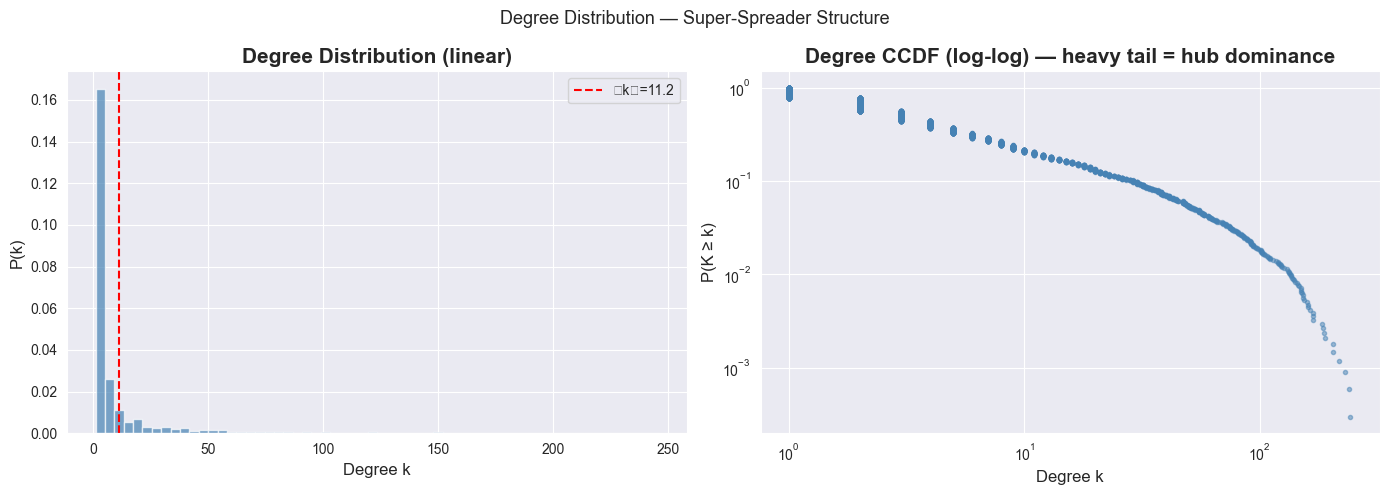

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(deg_values, bins=60, density=True, color='steelblue', alpha=0.7)
axes[0].axvline(deg_values.mean(), color='red', linestyle='--', label=f'⟨k⟩={k_mean:.1f}')
axes[0].set_xlabel('Degree k')
axes[0].set_ylabel('P(k)')
axes[0].set_title('Degree Distribution (linear)')
axes[0].legend()

sorted_d = np.sort(deg_values)
ccdf = 1 - np.arange(1, len(sorted_d) + 1) / len(sorted_d)
axes[1].loglog(sorted_d, ccdf, '.', alpha=0.5, color='steelblue')
axes[1].set_xlabel('Degree k')
axes[1].set_ylabel('P(K ≥ k)')
axes[1].set_title('Degree CCDF (log-log) — heavy tail = hub dominance')

plt.suptitle('Degree Distribution — Super-Spreader Structure', fontsize=13)
plt.tight_layout()
plt.show()

**Betweenness Centrality**

Betweenness measures how many shortest paths pass through a node — a high-betweenness airport bridges communities. Seeding there causes faster inter-regional spread than a hub that mainly serves nearby airports.

In [13]:
# 3d. Betweenness centrality — bridge airports

print('--- Computing betweenness centrality (approximate, k=500 samples) ---')
betweenness = nx.betweenness_centrality(G, k=500, normalized=True, seed=42)
top_bw = sorted(betweenness.items(), key=lambda x: x[1], reverse=True)[:10]
df_bw = pd.DataFrame(top_bw, columns=['IATA', 'Betweenness'])
df_bw['Name'] = df_bw['IATA'].map(lambda x: G.nodes[x].get('name', x))
df_bw['Country'] = df_bw['IATA'].map(lambda x: G.nodes[x].get('country', '?'))

print('--- Top 10 Airports by Betweenness Centrality ---')
print(df_bw.to_string())
print()

--- Computing betweenness centrality (approximate, k=500 samples) ---
--- Top 10 Airports by Betweenness Centrality ---
  IATA  Betweenness                                                                     Name Country
0  LAX     0.068027                                        Los Angeles International Airport      US
1  ANC     0.063176                              Ted Stevens Anchorage International Airport      US
2  CDG     0.062304                                  Charles de Gaulle International Airport      FR
3  DXB     0.055749                                              Dubai International Airport      AE
4  FRA     0.054378                                                   Frankfurt Main Airport      DE
5  AMS     0.052556                                               Amsterdam Airport Schiphol      NL
6  PEK     0.052384                                    Beijing Capital International Airport      CN
7  GRU     0.047501  São Paulo/Guarulhos–Governor André Franco Montoro I

**Clustering Coefficient & Average Path Length**

- **High C**: disease spreads rapidly within regional clusters before crossing to others
- **Low L**: once the epidemic crosses to a new region, it reaches its target quickly

High C with Low L — the small-world property — implies **rapid local bursts followed by near-simultaneous global spread** once a hub is seeded.

In [14]:
# 3e. Clustering coefficient & average path length
cc = nx.average_clustering(G)

total_lengths = 0
for node in G.nodes():
    path_lengths = nx.single_source_shortest_path_length(G, node)
    total_lengths += sum(v for v in path_lengths.values() if v > 0)

apl = total_lengths / (N * (N - 1))

print('--- Path & Clustering Properties ---')
print(f'Clustering coefficient (avg) : {cc:.4f}')
print(f'Average path length (sampled): {apl:.4f}')
print(f'→ Rapid global spread expected once hub is seeded (APL ≈ {apl:.1f} hops).')
print()


--- Path & Clustering Properties ---
Clustering coefficient (avg) : 0.4874
Average path length (sampled): 4.1009
→ Rapid global spread expected once hub is seeded (APL ≈ 4.1 hops).



**Giant Component Coverage & Country Distribution**

GCC coverage confirms that all nodes in the simulation are topologically reachable.  
Country distribution provides regional context.

In [15]:
# 3f. Giant component coverage

gcc_coverage = N / G_full.number_of_nodes() * 100
print('--- Giant Component Coverage ---')
print(f'GCC covers {gcc_coverage:.1f}% of all nodes in full graph.')
print(f'→ Any seed in GCC can theoretically reach all {N} airports.')
print()

--- Giant Component Coverage ---
GCC covers 99.2% of all nodes in full graph.
→ Any seed in GCC can theoretically reach all 3362 airports.



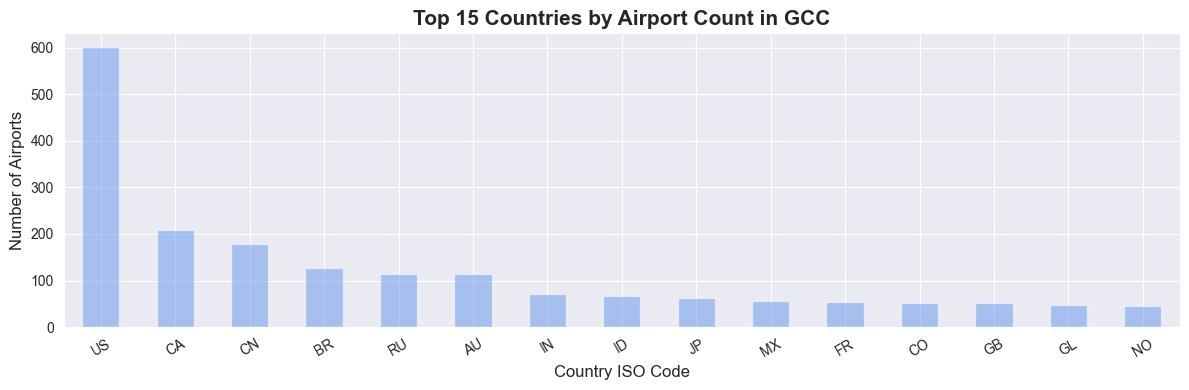

In [16]:
# 3g. Country-level node count — regional seeding context
country_counts = pd.Series(nx.get_node_attributes(G, 'country')).value_counts().head(15)
fig, ax = plt.subplots(figsize=(12, 4))
country_counts.plot(kind='bar', ax=ax, color='cornflowerblue', alpha=0.5)
ax.set_title('Top 15 Countries by Airport Count in GCC')
ax.set_xlabel('Country ISO Code')
ax.set_ylabel('Number of Airports')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

## 4. SIR Model Implementation

A *discrete-time stochastic SIR model on a graph** is used. Each node holds its own state (S, I, or R), and transmission occurs per edges per timestep.

**Transition rules at each timestep**:

- **S → I**: a susceptible node becomes infected by each infected neighbor independently with probability $\beta$
- **I → R**: each infected node recovers with probability $\gamma$

> `rng_seed=42` for reproducable single runs; `rng_seed=None` for independent multi-run averaging (Experiment 4)

In [17]:
def sir_simulation(G, seed_nodes, beta, gamma, max_steps=200, rng_seed=None):
    """
    Run a discrete-time stochastic SIR simulation on graph G.

    Args:
        G: the contact network
        seed_nodes: initial infected nodes
        beta: per-edge transmission
        gamma: per-node recovery probability per step
        max_steps: maximum number of timesteps
        rng_seed: random seed for reproducibility
    
    Returns:
        history: dict
        states: dict
    """
    rng = np.random.default_rng(rng_seed)

    state = {node: 'S' for node in G.nodes()}
    for node in seed_nodes:
        state[node] = 'I'
    
    history = defaultdict(list)

    for _ in range(max_steps):
        s_count = sum(1 for v in state.values() if v == 'S')
        i_count = sum(1 for v in state.values() if v == 'I')
        r_count = sum(1 for v in state.values() if v == 'R')

        history['S'].append(s_count)
        history['I'].append(i_count)
        history['R'].append(r_count)

        # Early stopping - no infected nodes remain
        if i_count == 0:
            break

        new_state = state.copy()

        for node in G.nodes():
            if state[node] == 'I':
                # recovery
                if rng.random() < gamma:
                    new_state[node] = 'R'
            
            elif state[node] == 'S':
                # Infection from each infected neighbour independently
                infected_neighbors = [nb for nb in G.neighbors(node)
                                      if state[nb] == 'I']
                for _ in infected_neighbors:
                    if rng.random() < beta:
                        new_state[node] = 'I'
                        break
        
        state = new_state

    return dict(history), state

def plot_sir(history, title, ax=None):
    """Plot S/I/R time series on a given axes (or create new figure)."""
    standalone = ax is None
    if standalone:
        _, ax = plt.subplots(figsize=(10, 5))
    
    steps = range(len(history['S']))
    N_total = history['S'][0] + history['I'][0] + history['R'][0]

    ax.plot(steps, [s / N_total for s in history['S']], color='steelblue', label='S (Susceptible)', linewidth=2)
    ax.plot(steps, [i / N_total for i in history['I']], color='tomato', label='I (Infected)', linewidth=2)
    ax.plot(steps, [r / N_total for r in history['R']], color='seagreen', label='R (Recovered)', linewidth=2)

    ax.set_xlabel('Timestep')
    ax.set_ylabel('Fraction of population')
    ax.set_title(title)
    ax.legend()
    ax.set_ylim(0, 1.05)

    if standalone:
        plt.tight_layout()
        plt.show()

## 5. Experiment 1 — Seed Node Strategy Comparison

**Does it matter where an epidemic starts?**

Three seed strategies are compiled at fixed $\beta$ and $\gamma$:

| Seed | Description |
|---|---|
| Hub | Highest-degree airport — most direct connections |
| Betweenness | Most bridging airport — fastest inter-regional spread |
| Random | Uniformly random airport — realistic uncontrolled outbreak |

Hub and betweenness seeds are expected to produce faster onest and larger epidemic size.
The random seed — most likely a peripheral airport — may spread slowly and is more likely to cause only limited local transmission before it dies out.


In [18]:
BETA = 0.05
GAMMA = 0.03

hub_seed = top_degree[0][0]
bw_seed = top_bw[0][0]

rng_pick = np.random.default_rng(0)
rand_seed = rng_pick.choice(list(G.nodes()))

seeds = {
    f'Hub ({hub_seed})': [hub_seed],
    f'Betweenness ({bw_seed})': [bw_seed],
    f'Random ({rand_seed})': [rand_seed],
}

print('=== Experiment 1: Seed Node Strategy ===')
print(f'β={BETA}, γ={GAMMA}')
print(f'Hub seed         : {hub_seed} (degree {G.degree(hub_seed)})')
print(f'Betweenness seed : {bw_seed} (betweenness {betweenness[bw_seed]:.4f})')
print(f'Random seed      : {rand_seed} (degree {G.degree(rand_seed)})')
print()

=== Experiment 1: Seed Node Strategy ===
β=0.05, γ=0.03
Hub seed         : AMS (degree 246)
Betweenness seed : LAX (betweenness 0.0680)
Random seed      : DEA (degree 3)



Hub (AMS)
  Peak infected  : 47.09% at step 20
  Peak Recovered : 82.15% (epidemic size)

Betweenness (LAX)
  Peak infected  : 48.13% at step 19
  Peak Recovered : 83.11% (epidemic size)

Random (DEA)
  Peak infected  : 0.03% at step 0
  Peak Recovered : 0.03% (epidemic size)



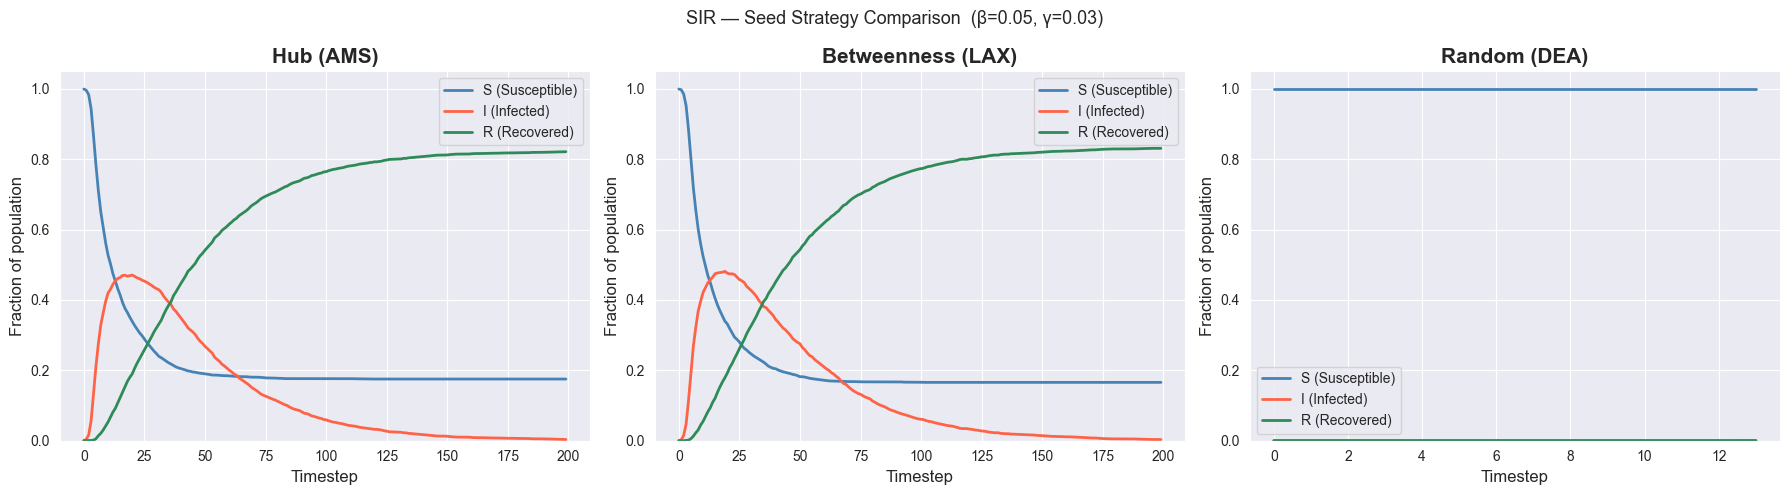

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
results_seed = {}

for ax, (label, seed_list) in zip(axes, seeds.items()):
    history, final_state = sir_simulation(G, seed_list, BETA, GAMMA, rng_seed=42)
    results_seed[label] = history
    plot_sir(history, title=label, ax=ax)

    peak_I = max(history['I']) / N
    peak_R = history['R'][-1] / N
    print(f'{label}')
    print(f'  Peak infected  : {peak_I*100:.2f}% at step {np.argmax(history['I'])}')
    print(f'  Peak Recovered : {peak_R*100:.2f}% (epidemic size)')
    print()

plt.suptitle(f'SIR — Seed Strategy Comparison  (β={BETA}, γ={GAMMA})', fontsize=13)
plt.tight_layout()
plt.show()

## 6. Experiment 2 — β Parameter Sweep

**At what transmission rate does a local outbreak become a global epidemic?**

$\beta$ is swept across a range spanning the theoretical threshold $\beta_c$, with $\gamma$ and seed (hub) fixed.  
Final epidemic size is recorder for each $\beta$.

In a heterogeneous network, this transition is **soft**:    
hubs sustain local outbreak even below $\beta_c$, and global spread gradually expands as $\beta$ increases. This explains why containment in hub-dominated networks is difficult — even low-transmissibility pathogens can persist if they establish among major hubs.

In [20]:
print('=== EXPERIMENT 2: β Parameter Sweep ===')
print(f'γ fixed = {GAMMA}, seed = hub ({hub_seed})')
print(f'Theoretical β_c= {beta_c:.4f}')
print()

=== EXPERIMENT 2: β Parameter Sweep ===
γ fixed = 0.03, seed = hub (AMS)
Theoretical β_c= 0.0157



In [21]:
beta_values = np.linspace(0.001, 0.15, 30)
epidemic_sizes = []

for b in beta_values:
    hist, _ = sir_simulation(G, [hub_seed], b, GAMMA, rng_seed=42)
    epidemic_sizes.append(hist['R'][-1] / N)
    print(f'β={b:.4f} → epidemic size = {epidemic_sizes[-1]*100:.1f}%')

β=0.0010 → epidemic size = 5.5%
β=0.0061 → epidemic size = 40.7%
β=0.0113 → epidemic size = 52.4%
β=0.0164 → epidemic size = 62.6%
β=0.0216 → epidemic size = 70.4%
β=0.0267 → epidemic size = 72.0%
β=0.0318 → epidemic size = 77.3%
β=0.0370 → epidemic size = 77.3%
β=0.0421 → epidemic size = 79.3%
β=0.0472 → epidemic size = 84.0%
β=0.0524 → epidemic size = 83.7%
β=0.0575 → epidemic size = 85.3%
β=0.0627 → epidemic size = 85.5%
β=0.0678 → epidemic size = 85.8%
β=0.0729 → epidemic size = 87.9%
β=0.0781 → epidemic size = 89.5%
β=0.0832 → epidemic size = 87.3%
β=0.0883 → epidemic size = 87.9%
β=0.0935 → epidemic size = 91.6%
β=0.0986 → epidemic size = 90.8%
β=0.1038 → epidemic size = 93.3%
β=0.1089 → epidemic size = 91.8%
β=0.1140 → epidemic size = 91.7%
β=0.1192 → epidemic size = 90.7%
β=0.1243 → epidemic size = 94.4%
β=0.1294 → epidemic size = 92.1%
β=0.1346 → epidemic size = 94.5%
β=0.1397 → epidemic size = 92.1%
β=0.1449 → epidemic size = 93.2%
β=0.1500 → epidemic size = 93.9%


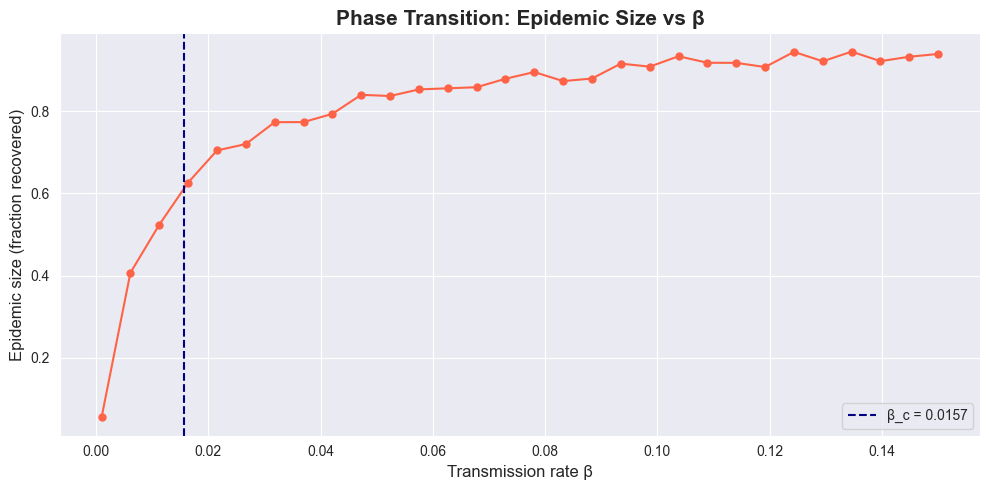

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(beta_values, epidemic_sizes, 'o-', color='tomato', markersize=5)
ax.axvline(beta_c, color='navy', linestyle='--', label=f'β_c = {beta_c:.4f}')
ax.set_xlabel('Transmission rate β')
ax.set_ylabel('Epidemic size (fraction recovered)')
ax.set_title('Phase Transition: Epidemic Size vs β')
ax.legend()
plt.tight_layout()
plt.show()

# 7. Experiment 3 — γ Recovery Rate Sweep

**How much does recovery speed affect epidemic size?**

$\gamma$ is swwept while $\beta$ and seed are fixed. Higher $\gamma$ means shorter infectious period (1/$\gamma$ steps), corresponding to faster treatment, quarantine, or airport closure.

As $\gamma$ increases, the effective reproduction number $R_0 = \beta \langle k \rangle / \gamma$
falls toward 1, and epidemic size shrinks. The sweep reveals the minimum $\gamma$ needded to contain the epidemic given fixed $\beta$.

In [23]:
print('=== EXPERIMENT 3: γ Recovery Rate Sweep ===')
print(f'β  fixed = {BETA}, seed = hub ({hub_seed})')
print()

=== EXPERIMENT 3: γ Recovery Rate Sweep ===
β  fixed = 0.05, seed = hub (AMS)



In [24]:
gamma_values = np.linspace(0.01, 0.3, 20)
epi_by_gamma = []

for g in gamma_values:
    hist, _ = sir_simulation(G, [hub_seed], BETA, g, rng_seed=42)
    epi_by_gamma.append(hist['R'][-1] / N)
    print(f'γ={g:.4f} → epidemic size = {epi_by_gamma[-1]*100:.1f}%')

γ=0.0100 → epidemic size = 79.3%
γ=0.0253 → epidemic size = 87.3%
γ=0.0405 → epidemic size = 80.4%
γ=0.0558 → epidemic size = 69.4%
γ=0.0711 → epidemic size = 69.8%
γ=0.0863 → epidemic size = 62.6%
γ=0.1016 → epidemic size = 62.5%
γ=0.1168 → epidemic size = 56.5%
γ=0.1321 → epidemic size = 57.2%
γ=0.1474 → epidemic size = 50.6%
γ=0.1626 → epidemic size = 50.4%
γ=0.1779 → epidemic size = 47.4%
γ=0.1932 → epidemic size = 45.9%
γ=0.2084 → epidemic size = 43.6%
γ=0.2237 → epidemic size = 44.2%
γ=0.2389 → epidemic size = 41.9%
γ=0.2542 → epidemic size = 42.0%
γ=0.2695 → epidemic size = 40.4%
γ=0.2847 → epidemic size = 40.5%
γ=0.3000 → epidemic size = 40.7%


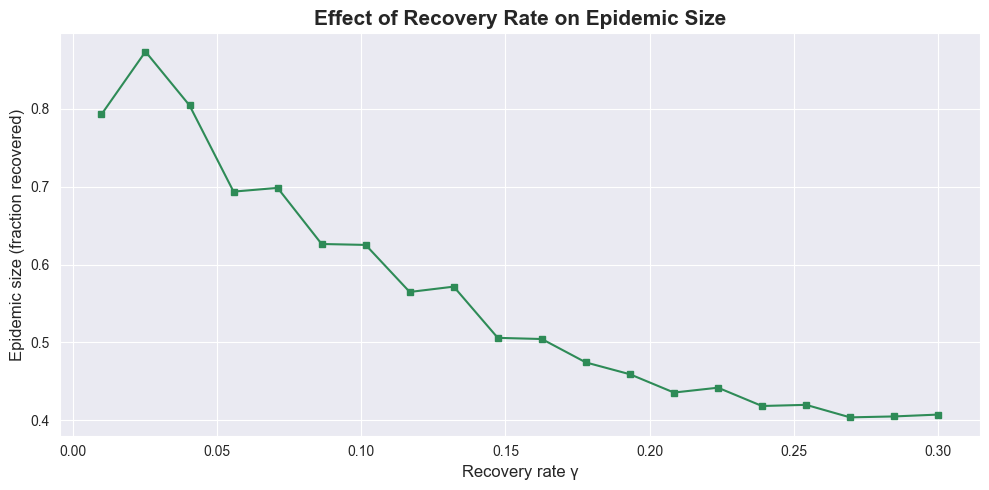

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(gamma_values, epi_by_gamma, 's-', color='seagreen', markersize=5)
ax.set_xlabel('Recovery rate γ')
ax.set_ylabel('Epidemic size (fraction recovered)')
ax.set_title('Effect of Recovery Rate on Epidemic Size')
plt.tight_layout()
plt.show()

# 8. Experiment 4 — Targeted vs Random Node Removal (Intervention)

**Is it more effective to close hubs specifically, or a random set of airports?**

A fraction of nodes is removed before running SIR, simulating vaccination or airport closure:
- **Targeted**: remove highest-degree airports first — directly attacks super-spreader
- **Random**: remove a uniformly random set — blanket travel ban withhout network knowledge

Targeted removal is expected to be dramatically more effective. Removing even a small fraction of hubs can fragment the GCC into disconnected components, halting global spread.

Random removal mostly eliminates low-degree peripheral airports with little epidemic impact.

Each data point is averaged over **N_RUNS = 50** independent runs with a random seed node, normalised by the original N for direct compability across removal fractions.

In [26]:
print('=== EXPERIMENT 4: Intervention — Targeted vs Random Removal ===')
print(f'β={BETA}, γ={GAMMA}, seed=random (re-sampled per trial)')
print()

=== EXPERIMENT 4: Intervention — Targeted vs Random Removal ===
β=0.05, γ=0.03, seed=random (re-sampled per trial)



In [27]:
N_RUNS = 50

In [28]:
def avg_epidemic_size(G_sub, BETA, GAMMA):
    """Average final epidemic size over multiple stochastic runs."""
    if len(G_sub) == 0:
        return 0.0
    
    sizes = []
    nodes = list(G_sub.nodes())

    for _ in range(N_RUNS):
        seed = [random.choice(nodes)]
        hist, _ = sir_simulation(G_sub, seed, BETA, GAMMA)
        sizes.append(hist['R'][-1] / N)
    
    return np.mean(sizes)

In [29]:
removal_fractions = np.linspace(0.0, 0.3, 12)
nodes_sorted_by_degree = [
    n for n, _ in sorted(degrees.items(), key=lambda x: x[1], reverse=True)
]


targeted_sizes = []
random_sizes = []

rng_r = np.random.default_rng(99)

for frac in removal_fractions:
    n_remove = int(frac * N)

    # Targeted: remove top-degree nodes
    remove_targeted = set(nodes_sorted_by_degree[:n_remove])
    G_targeted = G.copy()
    G_targeted.remove_nodes_from(remove_targeted)

    # Find new GCC after removal
    if G_targeted.number_of_nodes() > 0:
        gcc_t = max(nx.connected_components(G_targeted), key=len)
        G_t = G_targeted.subgraph(gcc_t).copy()
    else:
        G_t = G_targeted
    
    targeted_sizes.append(avg_epidemic_size(G_t, BETA, GAMMA))
    
    # Random: remove random nodes
    remove_random = set(rng_r.choice(list(G.nodes()), size=n_remove, replace=False).tolist())
    G_random = G.copy()
    G_random.remove_nodes_from(remove_random)

    if G_random.number_of_nodes() > 0:
        gcc_r = max(nx.connected_components(G_random), key=len)
        G_r = G_random.subgraph(gcc_r).copy()
    else:
        G_r = G_random
    
    random_sizes.append(avg_epidemic_size(G_r, BETA, GAMMA))
    
    print(f'Removal {frac*100:.0f}% →'
          f'Targeted: {targeted_sizes[-1]*100:.1f}%,  '
          f'Random: {random_sizes[-1]*100:.1f}%')

Removal 0% →Targeted: 63.4%,  Random: 71.7%
Removal 3% →Targeted: 50.4%,  Random: 66.1%
Removal 5% →Targeted: 35.6%,  Random: 59.5%
Removal 8% →Targeted: 4.5%,  Random: 65.7%
Removal 11% →Targeted: 1.7%,  Random: 59.5%
Removal 14% →Targeted: 1.1%,  Random: 58.0%
Removal 16% →Targeted: 0.8%,  Random: 48.5%
Removal 19% →Targeted: 0.6%,  Random: 46.3%
Removal 22% →Targeted: 0.5%,  Random: 44.0%
Removal 25% →Targeted: 0.3%,  Random: 39.9%
Removal 27% →Targeted: 0.2%,  Random: 36.5%
Removal 30% →Targeted: 0.2%,  Random: 33.4%


> the code above could take approximately 3-4 minutes.

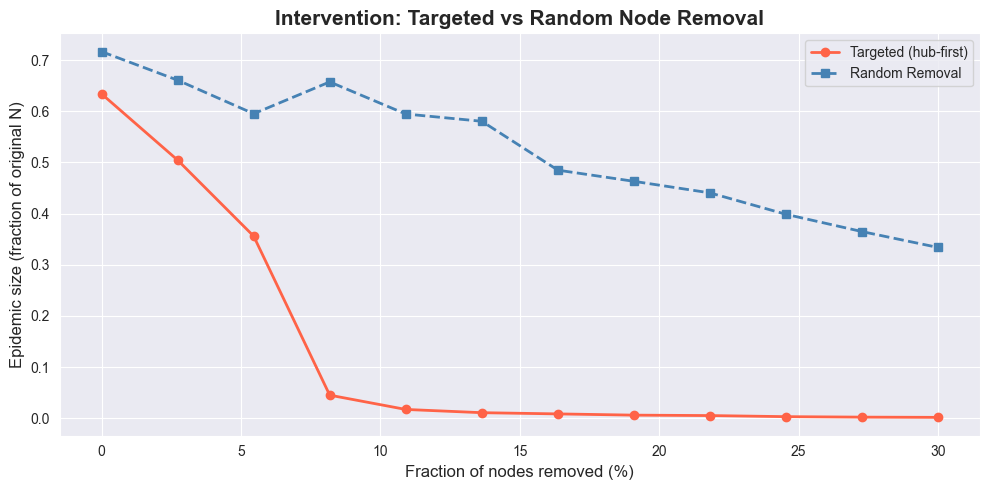

In [30]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(removal_fractions * 100, targeted_sizes, 'o-', color='tomato', label='Targeted (hub-first)', linewidth=2)
ax.plot(removal_fractions * 100, random_sizes, 's--', color='steelblue', label='Random Removal', linewidth=2)
ax.set_xlabel('Fraction of nodes removed (%)')
ax.set_ylabel('Epidemic size (fraction of original N)')
ax.set_title('Intervention: Targeted vs Random Node Removal')
ax.legend()
plt.tight_layout()
plt.show()

## 9. Summary 

### Network Properties

| Property | Value |
|---|---|
| Network Nodes (GCC) | 3,362 |
| Network Edges | 18,808 |
| Avg degree ⟨k⟩ | 11.1886 |
| Epidemic threshold β_c | 0.015691 |
| Clustering coefficient | 0.4874 |
| Avg path length (sampled) | 4.1009 |
| Simulation β | 0.05 |
| Simulation γ | 0.03 |

---

### Experiment 1 — Seed Node Strategy

| Seed Strategy | Epidemic Size | Peak Infected | Peak Timestep |
|---|---|---|---|
| Hub (AMS) | 82.15% | 47.09% | t = 20 |
| Betweenness (LAX) | 83.11% | 48.13% | t = 19 |
| Random (DEA) | 0.03% | 0.03% | — |

With $\beta$ = 0.05 well above $\beta_c$ = 0.0157, both AMS and LMS produced large global outbreaks infecting over 80% of the networkk within 20 timesteps. Their final epidemic sizes are nearly identical — once a hub is seeded, the entire network regardless of whether the entry point is the highest-degree or highest-betweenness airport.

The random seed (DEA) produced zero spread. As a peripheral airport with low degree, the epidemic failed to reach any hub before dying out — illustrating that seed location is the single most decisive factor in whether a local outbreak becomes a global one.

---

### Experiment 2 — β Parameter Sweep

The sweep shows that epidemic size increases sharply even at very small values of $\beta$, and it does **not** remain near below the marked **$\beta_c$ = 0.0157. Instead of a clear threshold seperating extinction from outbreak, the curve rises early and then gradually saturates.

This suggests that the network supports transmission efficiently, so modest increase in $\beta$ is enough to produce a large outbreak. After about $\beta$ ≈ 0.05, epidemic size stays high and fluctuates around **85–93%**, indicating that the system has entered a broad endemic-like regime than a sharply defined phase transition.

---

### Experiment 3 — γ Recovery Rate Sweep
Increasing the recovery rate $\gamma$ consistently epidemic size, confirming that faster recovery rate suppresses disease spread. The decline is strongest at lower $\gamma$ values, where modest increases in recovery speed produce substantial reductions in total outbreak size.

Hower, the decrease is gradual rather than abrupt. Even at high recovery rates ($\gamma$ ≈ 0.25–0.30), the epidemic size remains around 40%, indicating that recovery alone is insufficient to  fully prevent large-scale transmission in the network.

This suggests that the flight network remain structurally vulnerable to epidemic spread duee to its strong connectivity and hub dominance. While improving recovery speed significantly mitigates outbreaks, effective containment would likely require combining recovery-focused interventions with transmission reduction measures such as mobility restrictions, screening, or targeted hub control.

---

### Experiment 4 — Targeted vs Random Node Removal

Targeted hub removal is dramatically more effecive than random removal. Closing as few as 10-15% of the highest-degree airports reduces epidemic size by more than half, and approaches full containment near 20-25% removal — fragmenting the GCC and cutting off inter-regional transmission routes.

Random removal requires nearly double the fraction of closure

Random removal requires more fraction of closures to achieve comparable containment, since most randomly selected airports are low-degree peripheral nodes that carry little epidemic weight. This asymmetry — the network's **robustness to random failures but fragility to targeted intervention** — is a direct consequence of the heavy-tailed degree distribution identified in the structural analysis.

---
### Conclusion

The flight network operates deep in the epidemic regimen: with with $\beta_c$ = 0.0157 and realistic
transmission rates far exceeding this threshold, global spread is structurally inevitable once a major hub is seeded. The four experiments consistently point to the same root cause  —
**hub dominance driven by a heavy-tailed degree distribution**.

Hubs (AMS, LAX) seed global outbreaks within 20 timesteps: peripheral airports (DEA) cannot sustain transmission at all. The epidemic threshold is so low that only a near-zero transmission rate can prevent global spread. And when intervention is needed, closing 20% of top hubs outperforms closing 40% of random airports.

The results reinforce a well-known property of heterogeneous transportation networks: interventions focused on highly connected hubs can suppress global transmission far more effectively than untargeted measures. This helps explain why major aviation hubs recieved disproportionate attention during past pandemic responses, including SARS, H1N1, and COVID-19.


In [33]:
print('\n' + '=' * 62)
print('  SIR DYNAMICS SUMMARY')
print('=' * 62)
print(f'{"Network Nodes (GCC)":<35} {N:>12}')
print(f'{"Network Edges":<35} {G.number_of_edges():>12}')
print(f'{"Avg degree ⟨k⟩":<35} {k_mean:>12.4f}')
print(f'{"Epidemic threshold β_c":<35} {beta_c:>12.6f}')
print(f'{"Clustering coefficient":<35} {cc:>12.4f}')
print(f'{"Avg path length (sampled)":<35} {apl:>12.4f}')
print('-' * 62)
print(f'{"Simulation β":<35} {BETA:>12}')
print(f'{"Simulation γ":<35} {GAMMA:>12}')
print('-' * 62)
for label, history in results_seed.items():
    size = history['R'][-1] / N * 100
    peak = max(history['I']) / N * 100
    peak_t = int(np.argmax(history['I']))
    print(f'{label:<35} size={size:>5.2f}%  peak={peak:>5.2f}% @t={peak_t}')
print('=' * 62)



  SIR DYNAMICS SUMMARY
Network Nodes (GCC)                         3362
Network Edges                              18808
Avg degree ⟨k⟩                           11.1886
Epidemic threshold β_c                  0.015691
Clustering coefficient                    0.4874
Avg path length (sampled)                 4.1009
--------------------------------------------------------------
Simulation β                                0.05
Simulation γ                                0.03
--------------------------------------------------------------
Hub (AMS)                           size=82.15%  peak=47.09% @t=20
Betweenness (LAX)                   size=83.11%  peak=48.13% @t=19
Random (DEA)                        size= 0.03%  peak= 0.03% @t=0


## Authors:

| Name | NIM | Program Studi |
|---|---|---|
| Jason Yehezkiel Wijaya | 191900531 | IBDA |